# Skill Extraction using NLP

## Objective

The main objective of this notebook is to identify the technical skills most frequently requested in data-related job postings.

Job descriptions contain valuable information about the skills required by employers . Natural Language Processing (NLP) techniques are used to extract common words and phrases from job descriptions and build a skill dictionary.

## Questions

- What are the most frequently mentioned words in job descriptions?

- Which technical skills are the most commonly requested?
- Which technical skills are most demanded for each job category?
- Which technical skills are associated with higher salaries?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer

In [2]:
df = pd.read_csv('../data/processed/cleaned.csv')

In [3]:
df.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,...,Revenue,Competitors,Easy Apply,Min Salary (K),Max Salary (K),Average Salary (K),Average Employee Size,Job Category,Seniority,Is Core Data Role
0,Senior Data Scientist,$111K-$181K (Glassdoor est.),"ABOUT HOPPER\n\nAt Hopper, we’re on a mission ...",3.5,Hopper,"New York, NY","Montreal, Canada",501 to 1000 employees,2007.0,Company - Private,...,Unknown / Non-Applicable,NaN,NaN,111,181,146,750.0,Data Scientist,Senior,True
1,"Data Scientist, Product Analytics",$111K-$181K (Glassdoor est.),"At Noom, we use scientifically proven methods ...",4.5,Noom US,"New York, NY","New York, NY",1001 to 5000 employees,2008.0,Company - Private,...,Unknown / Non-Applicable,NaN,NaN,111,181,146,3000.0,Data Scientist,Unspecified,True
2,Data Science Manager,$111K-$181K (Glassdoor est.),Decode_M\n\nhttps://www.decode-m.com/\n\nData ...,NaN,Decode_M,"New York, NY","New York, NY",1 to 50 employees,NaN,Unknown,...,Unknown / Non-Applicable,NaN,True,111,181,146,26.0,Data Scientist,Manager,True
3,Data Analyst,$111K-$181K (Glassdoor est.),Sapphire Digital seeks a dynamic and driven mi...,3.4,Sapphire Digital,"Lyndhurst, NJ","Lyndhurst, NJ",201 to 500 employees,2019.0,Company - Private,...,Unknown / Non-Applicable,"Zocdoc, Healthgrades",NaN,111,181,146,350.0,Data Analyst,Unspecified,True
4,"Director, Data Science",$111K-$181K (Glassdoor est.),"Director, Data Science - (200537)\nDescription...",3.4,United Entertainment Group,"New York, NY","New York, NY",51 to 200 employees,2007.0,Company - Private,...,Unknown / Non-Applicable,"BBDO, Grey Group, Droga5",NaN,111,181,146,126.0,Data Scientist,Director,True


### Prepare the Text

Before extracting skills, the job descriptions are converted to lowercase and missing values are removed.

This standardization ensures that words such as **Python**, **python** and **PYTHON** are treated as the same token during analysis.

In [4]:
df_data_core = df[df['Is Core Data Role']]

In [5]:
job_description = df_data_core['Job Description'].dropna().str.lower()

## 1. What are the most frequently mentioned words in job descriptions?

Before any analysis we need to find the most repeated words in the dataset using Natural Language Processing. We search for the most frequently used one-word, two-word and three-word in the dataset.

After finding the top 100 unigrams, bigrams and trigrams we manually decide whether they are technical skills or not.

### Extract Frequent Unigrams

Some technical skills consist of a single word, such as Python, SQL, Spark and Tableau.

Unigram extraction is used to identify frequently occurring single-word terms in job description.

In [6]:
vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(1, 1),
    max_features=100
)

In [7]:
X = vectorizer.fit_transform(job_description)

In [8]:
unigrams = (
    pd.DataFrame({
        'Unigram': vectorizer.get_feature_names_out(),
        'Count': X.sum(axis=0).A1
    })
    .sort_values('Count', ascending=False)
)

In [9]:
unigrams.head()

,Unigram,Count
16,data,36605
26,experience,20267
96,work,9855
10,business,9825
85,team,7427


### Extract Frequent Bigrams

Many technical skills are represented by two-word phrases such as:
- Machine Learning
- Deep Learning
- Power BI

Bigram extraction helps identify these two-word technical skills.

In [10]:
vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(2, 2),
    max_features=100
)

In [11]:
X = vectorizer.fit_transform(job_description)

In [12]:
bigrams = (
    pd.DataFrame({
        'Bigram': vectorizer.get_feature_names_out(),
        'Count': X.sum(axis=0).A1
    })
    .sort_values('Count', ascending=False)
)

In [13]:
bigrams.head()

,Bigram,Count
60,machine learning,3196
30,data science,2822
99,years experience,2546
14,computer science,1639
31,data scientist,1501


### Extract Frequent Trigrams

Some technical concepts consist of three words such as:
- Natural Language Processing
- Artificial Intelligence Engineer

Trigram extraction helps identify more specific technical skills and domain concepts.

In [14]:
vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(3, 3),
    max_features=100
)

In [15]:
X = vectorizer.fit_transform(job_description)

In [16]:
trigrams = (
    pd.DataFrame({
        'Trigram': vectorizer.get_feature_names_out(),
        'Count': X.sum(axis=0).A1
    })
    .sort_values('Count', ascending=False)
)

In [17]:
trigrams.head()

,Trigram,Count
30,equal opportunity employer,984
80,sexual orientation gender,734
59,orientation gender identity,661
68,race color religion,657
71,regard race color,563


### Build Skill Dictionary

The extracted unigrams, bigrams and trigrams are manually reviewed to seperate technical skills from general terms.

The selected skills are used to create a skill dictionary for extracting skill-related features from job descriptions.

In [20]:
unigrams['Unigram'][:50]

16            data
26      experience
96            work
10        business
85            team
75          skills
99           years
20     development
72         science
2         analysis
0          ability
37       knowledge
4        analytics
66        required
39        learning
35             job
77       solutions
97         working
87       technical
68        research
31       including
82          strong
33     information
46             new
42      management
83         support
18          design
67    requirements
92           tools
95           using
63         related
19         develop
23     engineering
12         company
84         systems
41         machine
78             sql
44          models
90      technology
17          degree
24     environment
91            time
55         product
50        position
74        services
47     opportunity
86           teams
60          python
51       preferred
81          status
Name: Unigram, dtype: object

In [19]:
unigrams['Unigram'][50:]

71                role
76            software
59             provide
73           scientist
79         statistical
22          employment
13             complex
58            projects
14            computer
3           analytical
8                build
62             quality
69    responsibilities
57             project
48              people
29                help
53             process
94                 use
98               world
32            industry
27               field
6                based
88          techniques
61      qualifications
52            problems
7                 best
43            modeling
1             advanced
89        technologies
11       communication
38               large
28              health
9             building
56            products
93       understanding
30                high
49         performance
25               equal
64           reporting
70             results
65             reports
54           processes
15            customer
80         

In [20]:
bigrams['Bigram'][:50]

60         machine learning
30             data science
99         years experience
14         computer science
31           data scientist
45        equal opportunity
50       experience working
12     communication skills
17            data analysis
6                  big data
81       sexual orientation
64          national origin
58          job description
18             data analyst
54          gender identity
65     opportunity employer
47          experience data
91           veteran status
4           bachelor degree
33                data sets
19           data analytics
68          problem solving
72               race color
22            data engineer
76            related field
0              ability work
7     business intelligence
66       orientation gender
82           skills ability
11           color religion
21              data driven
32          data scientists
34             data sources
71     qualified applicants
5            best practices
94          work exp

In [21]:
bigrams['Bigram'][50:]

55            hands experience
43           employment regard
77                religion sex
70           protected veteran
51            experience years
92                work closely
59                 large scale
89               united states
15    consideration employment
44            equal employment
13                complex data
57           internal external
39             degree computer
74       receive consideration
3           applicants receive
40        education experience
26               data modeling
83           skills experience
61              marital status
38               deep learning
63               minimum years
62               master degree
97       written communication
96           working knowledge
86        statistical analysis
42      employment opportunity
9            business problems
10       business requirements
73                   real time
85              solving skills
27                 data models
98              written verbal
84      

In [22]:
trigrams['Trigram'][:50]

30          equal opportunity employer
80           sexual orientation gender
59         orientation gender identity
68                 race color religion
71                   regard race color
70    receive consideration employment
67        qualified applicants receive
4     applicants receive consideration
27              employment regard race
22             degree computer science
63            protected veteran status
17     consideration employment regard
11                  color religion sex
62              problem solving skills
28        equal employment opportunity
79              sex sexual orientation
26       employer qualified applicants
95        written communication skills
97               years experience data
1          affirmative action employer
39          gender identity expression
57      opportunity affirmative action
45                     large data sets
49             machine learning models
58      opportunity employer qualified
15            computer sc

In [23]:
trigrams['Trigram'][50:]

54         national origin disability
51              medical dental vision
5            bachelor degree computer
13                  complex data sets
75           science machine learning
21           data visualization tools
66     qualifications bachelor degree
35        experience years experience
24          disability veteran status
93          veteran status disability
77              senior data scientist
7               big data technologies
44         knowledge skills abilities
2          analytical problem solving
72                related field years
33                experience big data
78                sex national origin
76              science related field
73              religion sex national
89            technical non technical
40             gender identity gender
83    status characteristic protected
23       disability protected veteran
42         identity gender expression
46                   large scale data
65                proven track record
6           

**Note**

These skill lists are extracted by manually going through the unigrams, bigrams and trigrams.

In [21]:
skills = ['sql', 'python', 'statistics', 'machine learning', 'data science', 'computer science', 'data analysis',
          'communication skills', 'big data', 'bachelor degree', 'data analytics', 'problem solving',
          'business intelligence', 'data visualization', 'data mining', 'data pipelines', 'data engineering',
          'data management', 'decision making', 'data modeling', 'master degree', 'deep learning',
          'software development', 'statistical analysis', 'advanced analytics', 'project management',
          'data collection', 'natural language processing', 'computer science engineering',
          'verbal communication skills', 'analytical problem solving', 'large scale data',
          'computer science statistics']

In [22]:
technical_skills = [
    'sql',
    'python',
    'statistics',
    'machine learning',
    'data analysis',
    'big data',
    'data analytics',
    'business intelligence',
    'data visualization',
    'data mining',
    'data pipelines',
    'data engineering',
    'data management',
    'data modeling',
    'deep learning',
    'software development',
    'statistical analysis',
    'advanced analytics',
    'natural language processing'
]

In [23]:
domain_terms = [
    'data science',
    'computer science',
    'computer science engineering'
]

In [24]:
soft_skills = [
    'communication skills',
    'problem solving',
    'decision making',
    'verbal communication skills',
    'analytical problem solving'
]

In [25]:
education_terms = [
    'bachelor degree',
    'master degree'
]

### Extract Technical Skill Features

The technical skills identified from the NLP analysis are converted into binary features.

For each job posting, a value of:
- True: The skill is mentioned in the job description.
- False The skill is not mentioned in the job description.

This allows further analysis of skill demand in the data job market.

In [26]:
for skill in technical_skills:
    df[skill] = df['Job Description'].str.lower().str.contains(skill, na=False)

In [27]:
df[technical_skills].head()

,sql,python,statistics,machine learning,data analysis,big data,data analytics,business intelligence,data visualization,data mining,data pipelines,data engineering,data management,data modeling,deep learning,software development,statistical analysis,advanced analytics,natural language processing
0,True,False,True,True,False,True,False,True,True,True,False,False,False,False,False,False,False,False,False
1,True,True,False,True,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False
2,False,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,True,True,False,False,False,False,False,True,True,False,False,False,True,False,False,False,False,False,False
4,False,True,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False


In [28]:
## Further analysis on data core roles
df_data_core = df[df['Is Core Data Role']]

## 2. Which technical skills are the most commonly requested?

The number of job postings requiring each technical skill is calculated  by summing the binary features.

In [29]:
skill_demand = df_data_core[technical_skills].sum().sort_values(ascending=False)
skill_demand

python                         2019
sql                            2008
machine learning               1290
statistics                     1268
data analysis                   893
big data                        766
data visualization              545
data analytics                  498
business intelligence           470
data mining                     431
data engineering                385
data pipelines                  381
data modeling                   350
data management                 344
statistical analysis            324
software development            322
deep learning                   286
advanced analytics              250
natural language processing     195
dtype: int64

In [30]:
skill_summary = (
    pd.DataFrame({
        'Skill': skill_demand.index,
        'Job Count': skill_demand.values,
        'Percentage': (skill_demand.values / len(df) * 100).round(1)
    })
)
skill_summary

,Skill,Job Count,Percentage
0,python,2019,51.7
1,sql,2008,51.4
2,machine learning,1290,33.0
3,statistics,1268,32.4
4,data analysis,893,22.8
5,big data,766,19.6
6,data visualization,545,13.9
7,data analytics,498,12.7
8,business intelligence,470,12.0
9,data mining,431,11.0


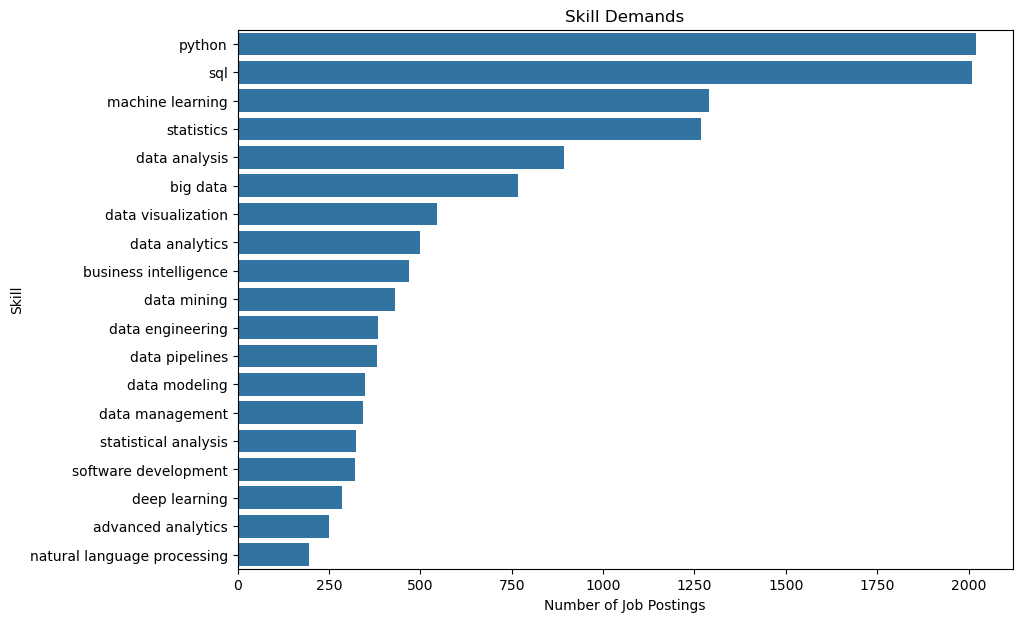

In [31]:
plt.figure(figsize=(10, 7))
sns.barplot(x=skill_demand.values, y=skill_demand.index)
plt.title('Skill Demands')
plt.xlabel('Number of Job Postings')
plt.ylabel('Skill')
plt.show()

### Insight

Python and SQL are the two most frequently requested technical skills, appearing in more than half of all job postings. This highlights their role as foundational skills across data-related positions.

Machine Learning and Statistics are also highly demanded, indicating that employers value both practical machine learning knowledge and strong statistical foundations.

Skills such as Data Engineering, Data Pipelines, Data Modeling, and Data Management appear less frequently than Python and SQL but remain important, reflecting the growing demand for data infrastructure and engineering expertise.

More specialized skills, including Deep Learning and Natural Language Processing, are requested less often, suggesting they are primarily required for specialized AI and machine learning roles rather than general data positions.

## 3. Which technical skills are most demanded for each job category?

Overall skill demand provides a general overview of the job market. However, different data roles require different technical skills.

In this section, technical skills are analyzed separately for each job category to identify the most frequently requested skills for different types of data-related positions.

In [32]:
skill_percentage = (
    (df_data_core.groupby(by='Job Category')[technical_skills]
        .sum()
        .div(df_data_core['Job Category'].value_counts(), axis=0) * 100)
        .round(1)
)
skill_percentage.head()

,sql,python,statistics,machine learning,data analysis,big data,data analytics,business intelligence,data visualization,data mining,data pipelines,data engineering,data management,data modeling,deep learning,software development,statistical analysis,advanced analytics,natural language processing
Job Category,,,,,,,,,,,,,,,,,,,
Analytics Consultant,60.7,41.0,18.0,32.8,27.9,18.0,9.8,23.0,19.7,23.0,0.0,3.3,11.5,18.0,3.3,8.2,3.3,3.3,0.0
Analytics Manager,71.4,34.7,24.5,8.2,14.3,4.1,24.5,20.4,20.4,4.1,4.1,0.0,4.1,12.2,2.0,6.1,2.0,10.2,0.0
Business Intelligence,79.7,32.9,26.6,2.5,27.8,8.9,10.1,89.9,35.4,13.9,0.0,5.1,16.5,16.5,0.0,5.1,2.5,0.0,0.0
Data Analyst,66.0,27.8,28.2,7.2,34.4,6.4,19.9,17.5,17.2,14.3,1.7,4.0,13.4,8.4,0.8,4.7,10.1,3.6,0.3
Data Architect,91.3,30.4,0.0,26.1,30.4,30.4,21.7,30.4,30.4,26.1,13.0,17.4,26.1,43.5,4.3,8.7,0.0,0.0,0.0


In [33]:
job_categories = df_data_core['Job Category'].value_counts().index

In [34]:
top_5_skills_dict = dict()
for job in job_categories:
    skill_list = (
        skill_percentage.loc[job]
        .sort_values(ascending=False)
        .head(5)
        .index
        .tolist()
    )
    top_5_skills_dict[job] = skill_list
top_5_skills = pd.DataFrame(top_5_skills_dict)
top_5_skills.T

,0,1,2,3,4
Data Scientist,python,machine learning,statistics,sql,data analysis
Data Engineer,python,sql,big data,data pipelines,data engineering
Data Analyst,sql,data analysis,statistics,python,data analytics
Machine Learning Scientist,data analysis,statistics,python,machine learning,statistical analysis
Research Scientist,machine learning,python,data analysis,statistics,deep learning
Machine Learning Engineer,machine learning,python,deep learning,sql,big data
Business Intelligence,business intelligence,sql,data visualization,python,data analysis
Analytics Consultant,sql,python,machine learning,data analysis,data mining
Quantitative Research,statistics,python,machine learning,statistical analysis,sql
Analytics Manager,sql,python,statistics,data analytics,business intelligence


### Insight

Technical skill requirements vary considerably across different data-related roles.

- **Data Scientist** positions primarily require Python, Machine Learning, Statistics, SQL, and Data Analysis, highlighting the combination of programming, statistical knowledge, and predictive modeling.

- **Data Engineer** roles emphasize SQL, Big Data, Data Pipelines, and Data Engineering, reflecting their focus on building and maintaining data infrastructure.

- **Data Analyst** positions prioritize SQL and Data Analysis, followed by Statistics and Python, indicating a stronger focus on querying, reporting, and analytical tasks.

- **Machine Learning Engineer** roles place Machine Learning and Deep Learning among the highest priorities, demonstrating the importance of specialized AI skills.

- **Business Intelligence** positions strongly emphasize Business Intelligence tools, SQL, and Data Visualization, which aligns with reporting and dashboard development responsibilities.

Overall, Python and SQL appear consistently across most job categories, confirming their role as fundamental technical skills in the data profession. However, specialized roles require additional domain-specific skills such as Deep Learning, Data Engineering, or Business Intelligence.

## 4. Which technical skills are associated with higher salaries?

In this section we find the skills that are associated with higher salary. We calculate the median salary for job postings requiring each skill.

In [35]:
skill_salary = pd.DataFrame({
    'Median Salary': df_data_core.groupby('Job Category')['Average Salary (K)'].median(),
    'Top 5 Skills': top_5_skills_dict
})
skill_salary.sort_values(by='Median Salary', ascending=False)

,Median Salary,Top 5 Skills
Data Scientist,125.0,"[python, machine learning, statistics, sql, da..."
Machine Learning Engineer,121.0,"[machine learning, python, deep learning, sql,..."
Data Visualization,110.0,"[sql, python, machine learning, advanced analy..."
Research Scientist,106.0,"[machine learning, python, data analysis, stat..."
Data Management,106.0,"[data management, sql, data analytics, data vi..."
Quantitative Research,105.0,"[statistics, python, machine learning, statist..."
Data Analyst,96.0,"[sql, data analysis, statistics, python, data ..."
Machine Learning Scientist,95.0,"[data analysis, statistics, python, machine le..."
Data Engineer,94.0,"[python, sql, big data, data pipelines, data e..."
Analytics Manager,92.0,"[sql, python, statistics, data analytics, busi..."


In [36]:
skill_salary.loc['Data Scientist']['Top 5 Skills']

['python', 'machine learning', 'statistics', 'sql', 'data analysis']

In [37]:
salary_by_skill = pd.Series()
for skill in technical_skills:
    salary_by_skill[skill] = df_data_core.groupby(skill)['Average Salary (K)'].median().get(True)

salary_by_skill = salary_by_skill.sort_values(ascending=False)
salary_by_skill

natural language processing    122.0
deep learning                  122.0
machine learning               122.0
statistics                     121.0
data mining                    118.0
statistical analysis           113.0
python                         112.0
data visualization             112.0
data analysis                  108.0
sql                            107.0
data analytics                 104.0
advanced analytics             104.0
data pipelines                 104.0
big data                       104.0
data engineering               104.0
business intelligence          100.0
data modeling                  100.0
software development           100.0
data management                 94.0
dtype: float64

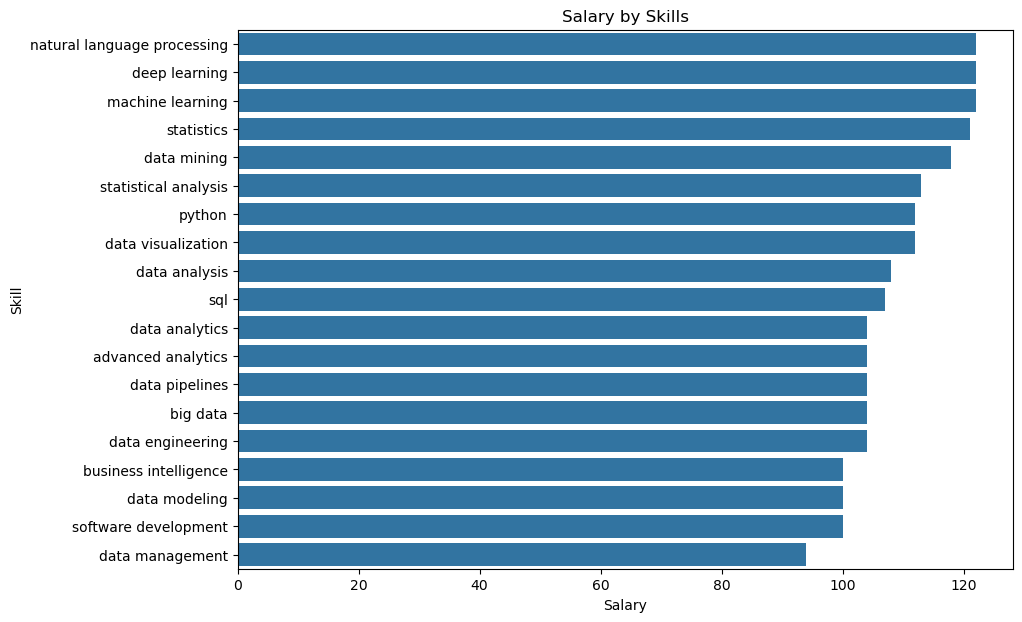

In [38]:
plt.figure(figsize=(10, 7))
sns.barplot(x=salary_by_skill.values, y=salary_by_skill.index)
plt.title('Salary by Skills')
plt.xlabel('Salary')
plt.ylabel('Skill')
plt.show()

### Insight

Job postings mentioning Machine Learning, Deep Learning, Natural Language Processing, and Statistics tend to offer the highest median salaries.

These skills are commonly associated with specialized AI and advanced analytics roles, which generally provide higher compensation than general data positions.

However, this analysis shows an association rather than a causal relationship. Higher salaries may also be influenced by other factors such as seniority, industry, company, or job category.

### Save New Dataset with Skills

In [39]:
df.to_csv('../data/processed/feature_engineered.csv', index=False)

# Conclusion

This notebook used Natural Language Processing (NLP) techniques to extract technical skills from job descriptions and analyze skill demand in the data job market.

### Key Findings

- Python and SQL are the two most frequently requested technical skills, appearing in more than half of all job postings.
- Machine Learning and Statistics are also highly demanded, highlighting the importance of analytical and predictive modeling skills.
- Technical skill requirements vary across job categories:
  - Data Scientists emphasize Python, Machine Learning, Statistics, and SQL.
  - Data Engineers focus on SQL, Big Data, Data Pipelines, and Data Engineering.
  - Data Analysts primarily require SQL, Data Analysis, Statistics, and Python.
- Specialized skills such as Deep Learning and Natural Language Processing appear less frequently but are associated with higher median salaries.
- Job postings requiring advanced AI-related skills generally offer higher compensation than general data roles.

### Limitations

- Skills were identified using keyword matching, which may miss synonyms or different writing styles.
- Salary differences show an association with skills rather than a causal relationship, since salary is also influenced by factors such as seniority, industry, company, and location.

### Next Step

The extracted technical skill features will be used in the salary prediction model to investigate how different skills contribute to salary estimation and feature importance.